In [90]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler

from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_val_score

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

In [91]:
df = pd.read_csv("train.csv")

In [92]:
df.head()

,Unnamed: 0,id,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,...,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
0,0,70172,Male,Loyal Customer,13,Personal Travel,Eco Plus,460,3,4,...,5,4,3,4,4,5,5,25,18.0,neutral or dissatisfied
1,1,5047,Male,disloyal Customer,25,Business travel,Business,235,3,2,...,1,1,5,3,1,4,1,1,6.0,neutral or dissatisfied
2,2,110028,Female,Loyal Customer,26,Business travel,Business,1142,2,2,...,5,4,3,4,4,4,5,0,0.0,satisfied
3,3,24026,Female,Loyal Customer,25,Business travel,Business,562,2,5,...,2,2,5,3,1,4,2,11,9.0,neutral or dissatisfied
4,4,119299,Male,Loyal Customer,61,Business travel,Business,214,3,3,...,3,3,4,4,3,3,3,0,0.0,satisfied


In [93]:
df.shape

(103904, 25)

In [94]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 103904 entries, 0 to 103903
Data columns (total 25 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   Unnamed: 0                         103904 non-null  int64  
 1   id                                 103904 non-null  int64  
 2   Gender                             103904 non-null  object 
 3   Customer Type                      103904 non-null  object 
 4   Age                                103904 non-null  int64  
 5   Type of Travel                     103904 non-null  object 
 6   Class                              103904 non-null  object 
 7   Flight Distance                    103904 non-null  int64  
 8   Inflight wifi service              103904 non-null  int64  
 9   Departure/Arrival time convenient  103904 non-null  int64  
 10  Ease of Online booking             103904 non-null  int64  
 11  Gate location                      1039

In [95]:
df.describe()

,Unnamed: 0,id,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes
count,103904.000000,103904.000000,103904.000000,103904.000000,103904.000000,103904.000000,103904.000000,103904.000000,103904.000000,103904.000000,103904.000000,103904.000000,103904.000000,103904.000000,103904.000000,103904.000000,103904.000000,103904.000000,103904.000000,103594.000000
mean,51951.500000,64924.210502,39.379706,1189.448375,2.729683,3.060296,2.756901,2.976883,3.202129,3.250375,3.439396,3.358158,3.382363,3.351055,3.631833,3.304290,3.640428,3.286351,14.815618,15.178678
std,29994.645522,37463.812252,15.114964,997.147281,1.327829,1.525075,1.398929,1.277621,1.329533,1.349509,1.319088,1.332991,1.288354,1.315605,1.180903,1.265396,1.175663,1.312273,38.230901,38.698682
min,0.000000,1.000000,7.000000,31.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,25975.750000,32533.750000,27.000000,414.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,3.000000,3.000000,3.000000,2.000000,0.000000,0.000000
50%,51951.500000,64856.500000,40.000000,843.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,4.000000,4.000000,4.000000,4.000000,4.000000,3.000000,4.000000,3.000000,0.000000,0.000000
75%,77927.250000,97368.250000,51.000000,1743.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,5.000000,4.000000,4.000000,4.000000,5.000000,4.000000,5.000000,4.000000,12.000000,13.000000
max,103903.000000,129880.000000,85.000000,4983.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,1592.000000,1584.000000


In [96]:

df.drop("Unnamed: 0", axis=1, inplace=True)

In [97]:
df.head()

,id,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,...,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
0,70172,Male,Loyal Customer,13,Personal Travel,Eco Plus,460,3,4,3,...,5,4,3,4,4,5,5,25,18.0,neutral or dissatisfied
1,5047,Male,disloyal Customer,25,Business travel,Business,235,3,2,3,...,1,1,5,3,1,4,1,1,6.0,neutral or dissatisfied
2,110028,Female,Loyal Customer,26,Business travel,Business,1142,2,2,2,...,5,4,3,4,4,4,5,0,0.0,satisfied
3,24026,Female,Loyal Customer,25,Business travel,Business,562,2,5,5,...,2,2,5,3,1,4,2,11,9.0,neutral or dissatisfied
4,119299,Male,Loyal Customer,61,Business travel,Business,214,3,3,3,...,3,3,4,4,3,3,3,0,0.0,satisfied


In [98]:
Missing Data Analysis

SyntaxError: invalid syntax (2740525114.py, line 1)

In [99]:
df.isnull().sum()

id                                     0
Gender                                 0
Customer Type                          0
Age                                    0
Type of Travel                         0
Class                                  0
Flight Distance                        0
Inflight wifi service                  0
Departure/Arrival time convenient      0
Ease of Online booking                 0
Gate location                          0
Food and drink                         0
Online boarding                        0
Seat comfort                           0
Inflight entertainment                 0
On-board service                       0
Leg room service                       0
Baggage handling                       0
Checkin service                        0
Inflight service                       0
Cleanliness                            0
Departure Delay in Minutes             0
Arrival Delay in Minutes             310
satisfaction                           0
dtype: int64

In [100]:
df["Arrival Delay in Minutes"] = df["Arrival Delay in Minutes"].fillna(
    df["Arrival Delay in Minutes"].median()
)

In [101]:
df["Arrival Delay in Minutes"].isnull().sum()

np.int64(0)

Outlier Detection

In [102]:
numeric_columns = df.select_dtypes(include=np.number).columns

print(numeric_columns)

Index(['id', 'Age', 'Flight Distance', 'Inflight wifi service',
       'Departure/Arrival time convenient', 'Ease of Online booking',
       'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort',
       'Inflight entertainment', 'On-board service', 'Leg room service',
       'Baggage handling', 'Checkin service', 'Inflight service',
       'Cleanliness', 'Departure Delay in Minutes',
       'Arrival Delay in Minutes'],
      dtype='object')


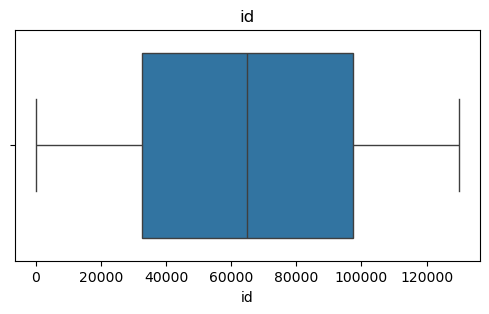

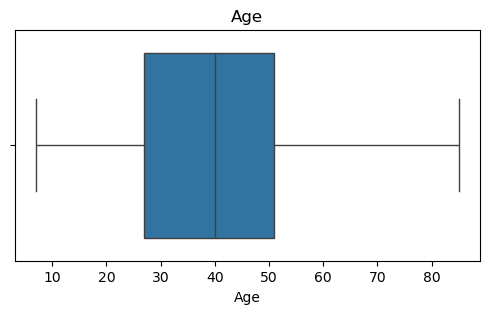

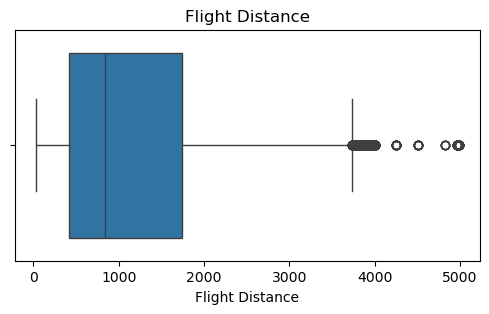

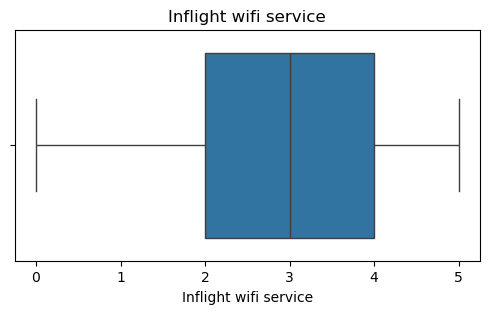

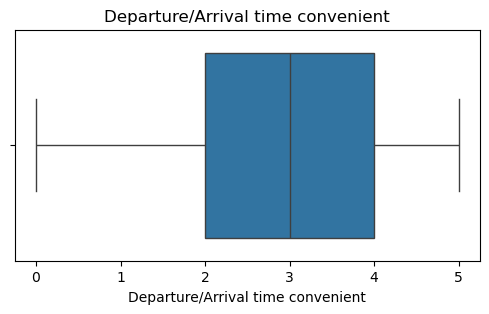

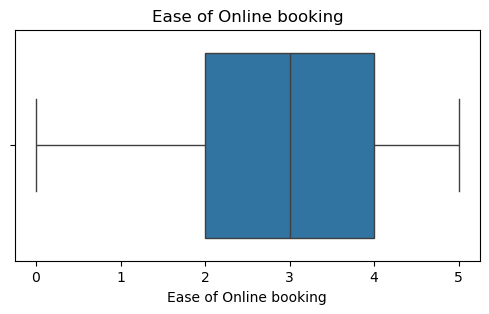

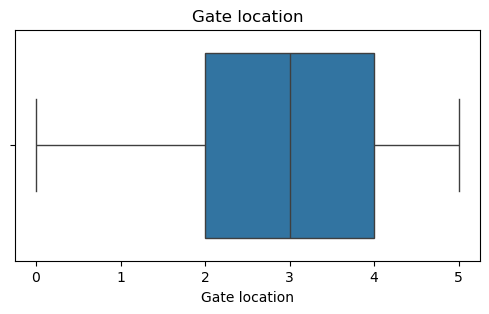

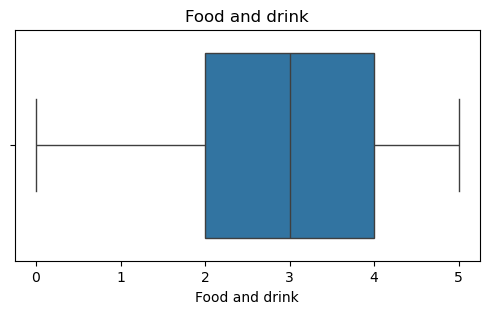

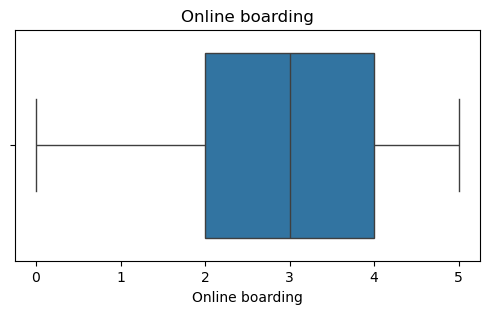

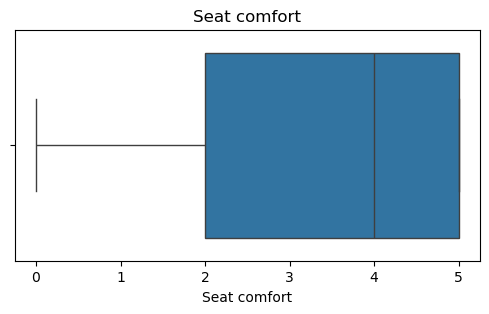

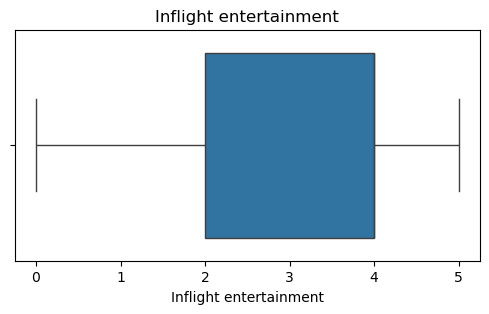

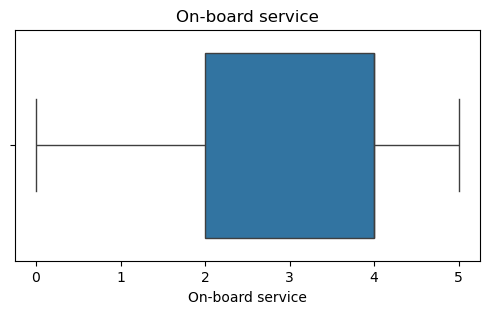

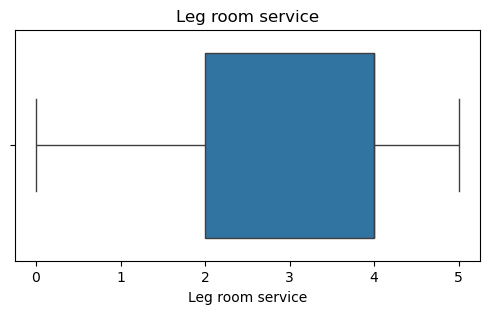

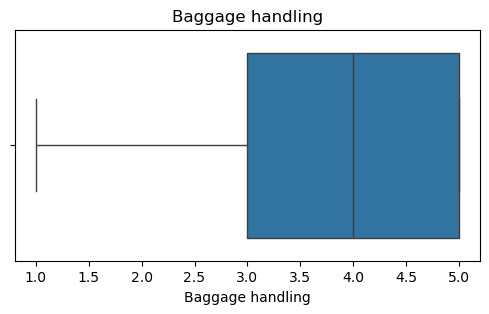

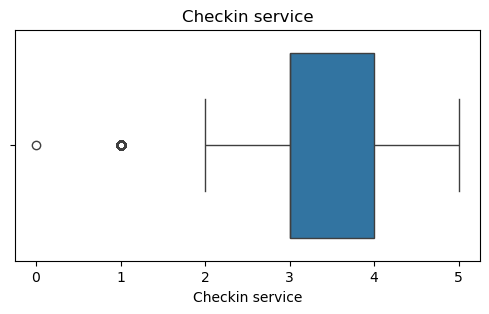

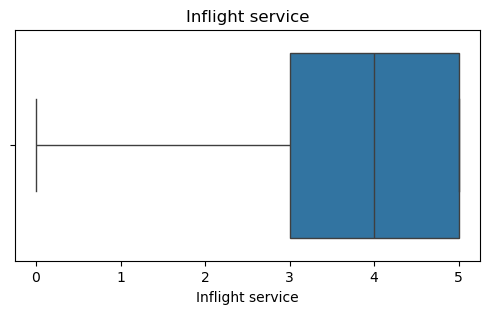

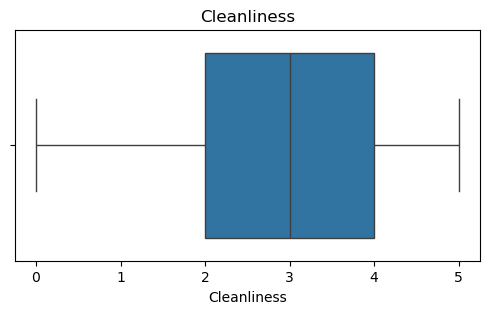

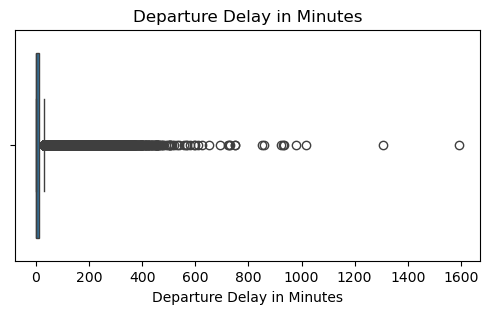

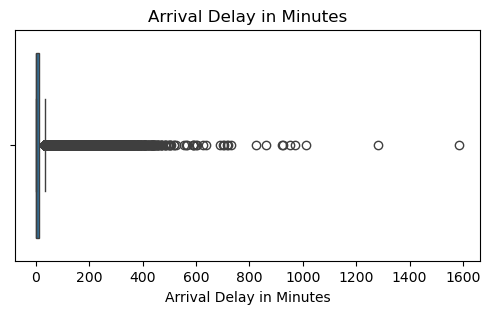

In [103]:
for column in numeric_columns:
    plt.figure(figsize=(6,3))
    sns.boxplot(x=df[column])
    plt.title(column)
    plt.show()

Removing Outliers Using IQR Method

In [104]:
Q1 = df["Flight Distance"].quantile(0.25)

Q3 = df["Flight Distance"].quantile(0.75)

IQR = Q3-Q1


lower_limit = Q1 - 1.5*IQR

upper_limit = Q3 + 1.5*IQR


df = df[
    (df["Flight Distance"] >= lower_limit)
    &
    (df["Flight Distance"] <= upper_limit)
]

In [105]:
df.shape

(101613, 24)

Data Analysis

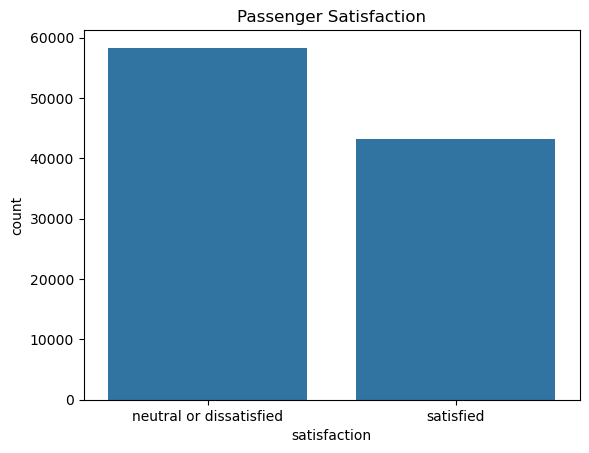

In [106]:
#Satisfaction Distribution
sns.countplot(
    x="satisfaction",
    data=df
)

plt.title("Passenger Satisfaction")

plt.show()

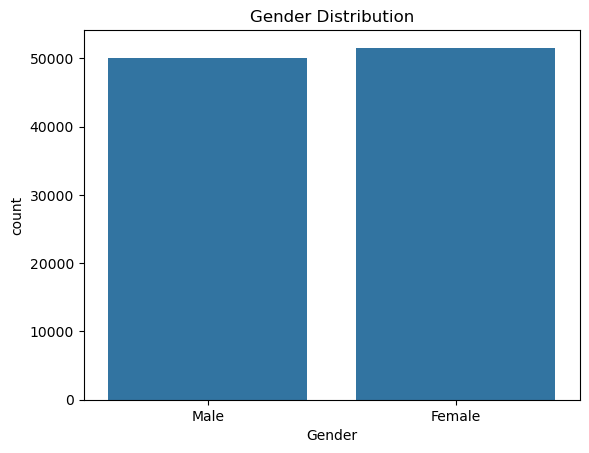

In [107]:
#Gender Analysis
sns.countplot(
    x="Gender",
    data=df
)

plt.title("Gender Distribution")

plt.show()

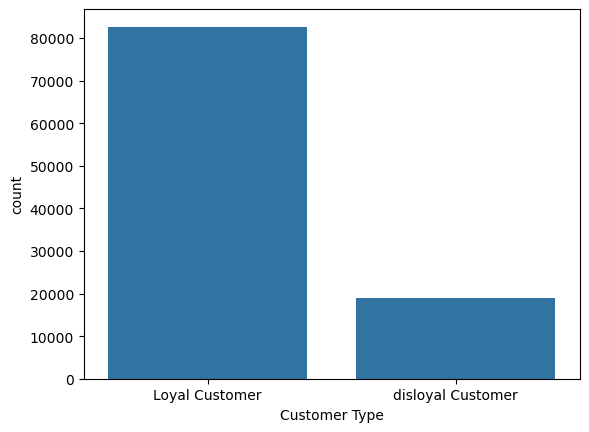

In [108]:
#Customer Type
sns.countplot(
    x="Customer Type",
    data=df
)

plt.show()

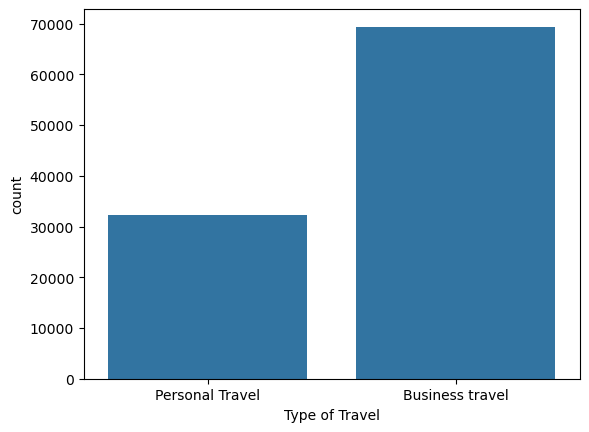

In [109]:
#Travel Type
sns.countplot(
    x="Type of Travel",
    data=df
)

plt.show()

Data Visualization

<Axes: xlabel='Age', ylabel='Count'>

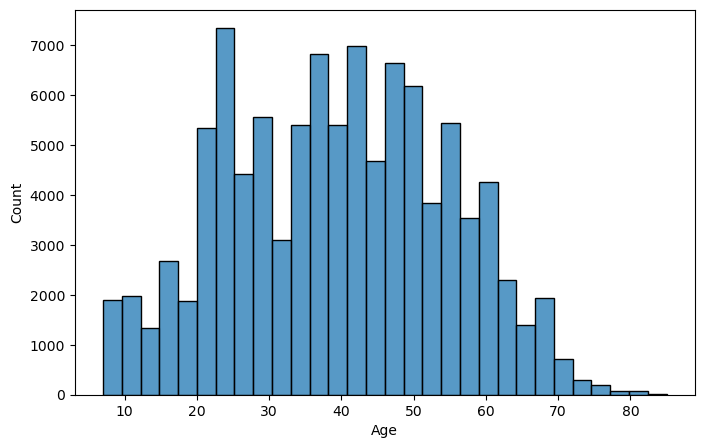

In [110]:
#Age Distribution
plt.figure(figsize=(8,5))

sns.histplot(
    df["Age"],
    bins=30
)

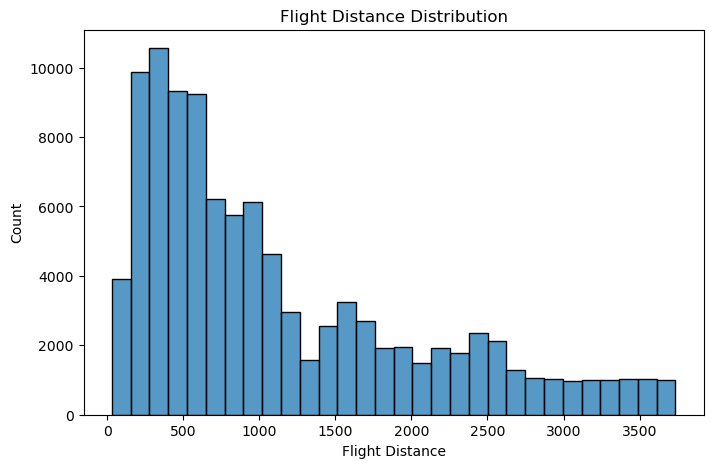

In [111]:
#Flight Distance Distribution
plt.figure(figsize=(8,5))

sns.histplot(
    df["Flight Distance"],
    bins=30
)

plt.title("Flight Distance Distribution")

plt.show()

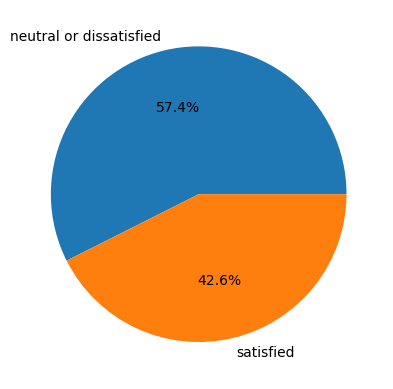

In [112]:
#Satisfaction Percentage
df["satisfaction"].value_counts().plot(
    kind="pie",
    autopct="%1.1f%%"
)

plt.ylabel("")

plt.show()

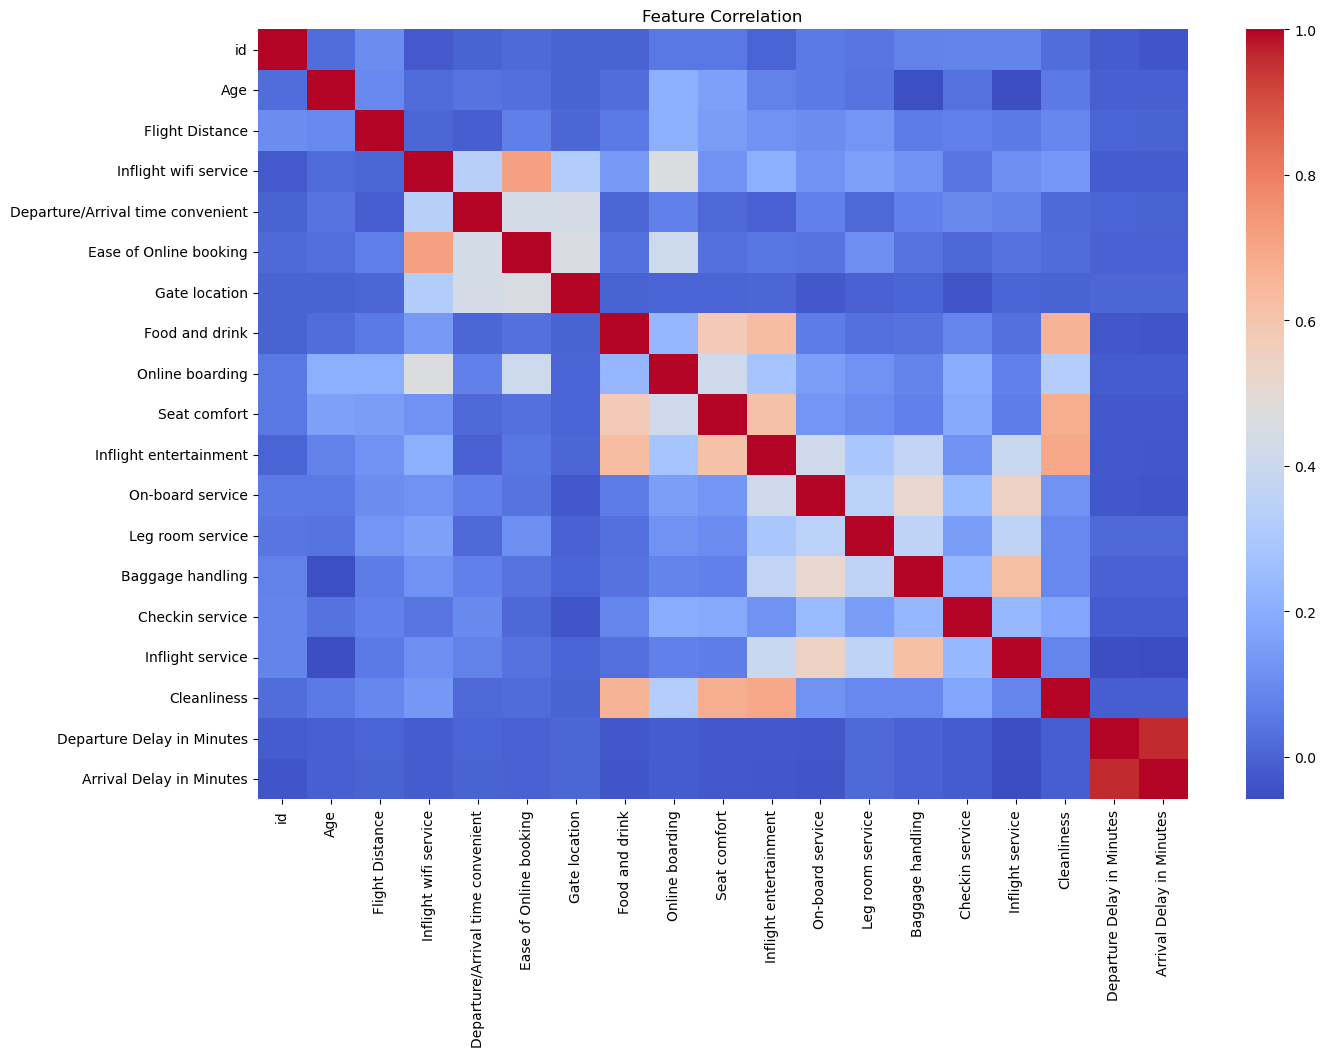

In [113]:
#Correlation Heatmap
plt.figure(figsize=(15,10))

sns.heatmap(
    df.corr(numeric_only=True),
    cmap="coolwarm"
)

plt.title("Feature Correlation")

plt.show()

Encoding

In [114]:
#Check categorical columns:

df.select_dtypes(
    include="object"
).columns

Index(['Gender', 'Customer Type', 'Type of Travel', 'Class', 'satisfaction'], dtype='object')

In [115]:
encoder = LabelEncoder()


for column in df.select_dtypes(include="object"):
    
    df[column] = encoder.fit_transform(
        df[column]
    )

Feature and Target Selection

In [116]:
#Input features:

X = df.drop(
    "satisfaction",
    axis=1
)



In [117]:
#Target:

y = df["satisfaction"]

Train Test Split

In [118]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

Feature Scaling

In [119]:
scaler = StandardScaler()


X_train = scaler.fit_transform(X_train)

X_test = scaler.transform(X_test)

Machine Learning Model 1
Logistic Regression


In [120]:
lr = LogisticRegression(
    max_iter=1000
)


lr.fit(
    X_train,
    y_train
)


lr_prediction = lr.predict(
    X_test
)


lr_accuracy = accuracy_score(
    y_test,
    lr_prediction
)


print(
    "Logistic Regression Accuracy:",
    lr_accuracy
)

Logistic Regression Accuracy: 0.8766422280175171


Machine Learning Model 2
Decision Tree

In [121]:
dt = DecisionTreeClassifier(
    random_state=42
)


dt.fit(
    X_train,
    y_train
)


dt_prediction = dt.predict(
    X_test
)


dt_accuracy = accuracy_score(
    y_test,
    dt_prediction
)


print(
    "Decision Tree Accuracy:",
    dt_accuracy
)

Decision Tree Accuracy: 0.9441027407370959


Machine Learning Model 3
Random Forest

In [127]:
rf = RandomForestClassifier(
    random_state=42
)


rf.fit(
    X_train,
    y_train
)


rf_prediction = rf.predict(
    X_test
)


rf_accuracy = accuracy_score(
    y_test,
    rf_prediction
)


print(
    "Random Forest Accuracy:",
    rf_accuracy
)

Random Forest Accuracy: 0.9636372582787974


Cross Validation
Logistic Regression

In [128]:
lr_cv = cross_val_score(
    lr,
    X,
    y,
    cv=5
)

print(
    lr_cv.mean()
)

C:\ProgramData\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
C:\ProgramData\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please als

0.8371469408943215


C:\ProgramData\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [129]:
#Decision Tree
dt_cv = cross_val_score(
    dt,
    X,
    y,
    cv=5
)

print(
    dt_cv.mean()
)

0.9451940347522925


In [133]:
#Random Forest
rf_cv = cross_val_score(
    rf,
    X,
    y,
    cv=5
)

print(
    rf_cv.mean()
)

0.9629771925263118


Confusion Matrix

Using Random Forest:

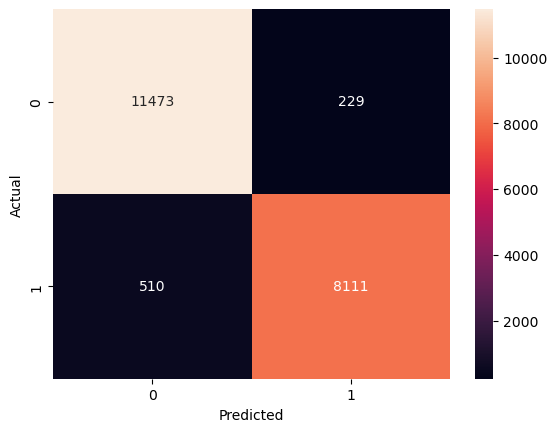

In [134]:
cm = confusion_matrix(
    y_test,
    rf_prediction
)


sns.heatmap(
    cm,
    annot=True,
    fmt="d"
)

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.show()

Classification Report

In [135]:
print(
    classification_report(
        y_test,
        rf_prediction
    )
)

              precision    recall  f1-score   support

           0       0.96      0.98      0.97     11702
           1       0.97      0.94      0.96      8621

    accuracy                           0.96     20323
   macro avg       0.96      0.96      0.96     20323
weighted avg       0.96      0.96      0.96     20323



Model Comparison

In [136]:
comparison = pd.DataFrame({

"Algorithm":[
    "Logistic Regression",
    "Decision Tree",
    "Random Forest"
],

"Accuracy":[
    lr_accuracy,
    dt_accuracy,
    rf_accuracy
]

})


comparison

,Algorithm,Accuracy
0,Logistic Regression,0.876642
1,Decision Tree,0.944103
2,Random Forest,0.963637


Accuracy Visualization

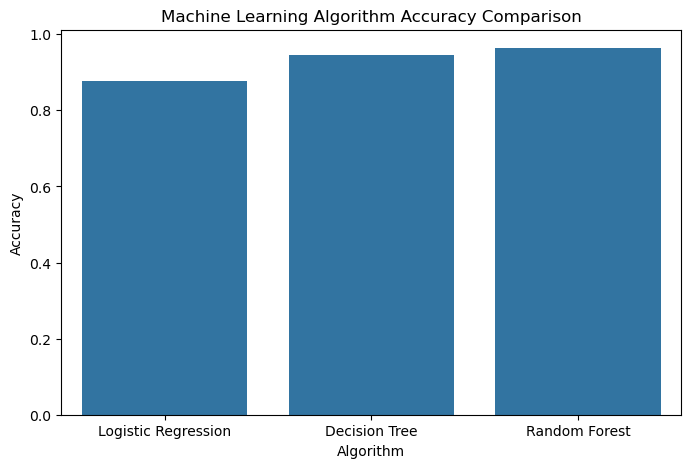

In [137]:
plt.figure(figsize=(8,5))


sns.barplot(
    data=comparison,
    x="Algorithm",
    y="Accuracy"
)


plt.title(
    "Machine Learning Algorithm Accuracy Comparison"
)


plt.show()